# 시뮬레이션
시뮬레이션 설계 방향

기본 아이디어: 지금까지 구한 회귀계수(복합충격 그룹, 통신기기부품 국가별)를 이용해서, "만약 이런 상황이 온다면 수출이 얼마나 변할까?"를 계산

시나리오 예시

시나리오	내용
금리 충격	미국금리 추가 +1%p 인상
유가 충격	두바이유 +20% 급등 (지정학 리스크 가정)
환율 충격	원/달러 환율 +10% 상승 (원화 약세)
복합 충격	위 세 가지가 동시에 발생 (2022년 3고위기 재현 가정)

각 시나리오별로 회귀계수를 곱해서 예상 수출 변화(%)를 계산하고, 이걸 품목군별(복합충격 그룹 vs 나머지)로 비교하면 "리스크에 가장 취약한 품목이 무엇인지" 인사이트가 나와요.

In [17]:
import pandas as pd

df = pd.read_csv('./data/final_df.csv')
df = df.drop(df.columns[0], axis=1)
df.head()

,날짜,HS코드,품목명,충격유형,국가코드,국가명,수출금액,수출중량,수입금액,수입중량,...,수출금액_log,원/달러환율_변화율,한국금리_변화율,미국금리_변화율,Dubai_변화율,원/달러환율_변화율_lag1,한국금리_변화율_lag1,미국금리_변화율_lag1,Dubai_변화율_lag1,시기
0,2019-02,271121,LNG액화,유가,AE,UAE,0.0,0.0,0.0,0.0,...,0.0,0.039845,0.0,0.000000,-1.622638,NaN,NaN,NaN,NaN,코로나 충격기
1,2019-03,271121,LNG액화,유가,AE,UAE,0.0,0.0,0.0,0.0,...,0.0,0.737045,0.0,0.416667,15.161934,0.039845,0.0,0.000000,-1.622638,코로나 충격기
2,2019-04,271121,LNG액화,유가,AE,UAE,0.0,0.0,0.0,0.0,...,0.0,0.904733,0.0,0.414938,5.979599,0.737045,0.0,0.416667,15.161934,코로나 충격기
3,2019-05,271121,LNG액화,유가,AE,UAE,0.0,0.0,0.0,0.0,...,0.0,3.710984,0.0,-1.239669,-10.704564,0.904733,0.0,0.414938,5.979599,코로나 충격기
4,2019-06,271121,LNG액화,유가,AE,UAE,0.0,0.0,0.0,0.0,...,0.0,-0.648589,0.0,-0.418410,-7.360541,3.710984,0.0,-1.239669,-10.704564,코로나 충격기


In [10]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["font.family"] = "NanumGothic"  # 한글 폰트
matplotlib.rcParams["axes.unicode_minus"] = False      # 마이너스 기호 깨짐 방지

            시나리오  예상 수출 변화(log)
0           금리충격         -0.192
1           유가충격          0.484
2           환율충격         -0.256
3  복합충격(3고위기 재현)         -0.022


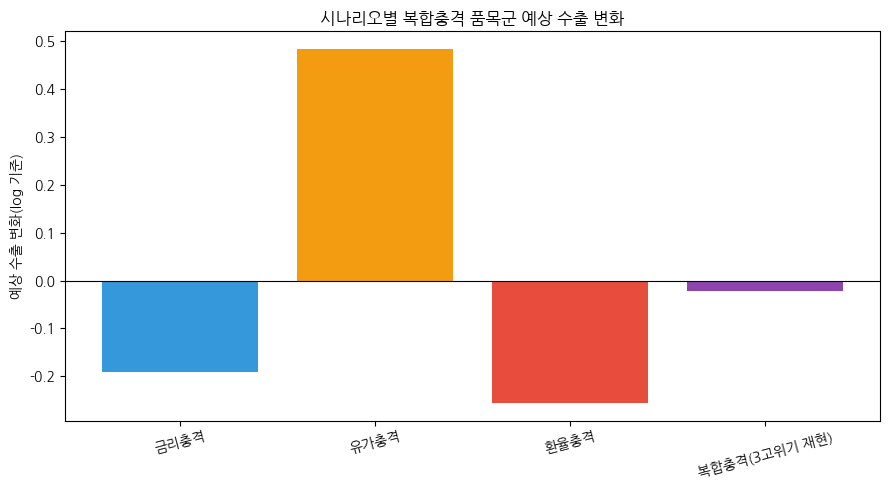

In [11]:
# 복합충격 그룹 회귀계수 (아까 구한 값)
coef_complex = {
    "원/달러환율_변화율": -0.0256,
    "한국금리_변화율": -0.0116,
    "미국금리_변화율": -0.0192,
    "Dubai_변화율": 0.0242
}

# 시나리오 정의 (변화율 % 기준)
scenarios = {
    "금리충격": {"원/달러환율_변화율": 0, "한국금리_변화율": 0, "미국금리_변화율": 10, "Dubai_변화율": 0},
    "유가충격": {"원/달러환율_변화율": 0, "한국금리_변화율": 0, "미국금리_변화율": 0, "Dubai_변화율": 20},
    "환율충격": {"원/달러환율_변화율": 10, "한국금리_변화율": 0, "미국금리_변화율": 0, "Dubai_변화율": 0},
    "복합충격(3고위기 재현)": {"원/달러환율_변화율": 10, "한국금리_변화율": 5, "미국금리_변화율": 10, "Dubai_변화율": 20},
}

# 시나리오별 예상 수출 변화(log 기준) 계산
sim_results = []
for scenario_name, changes in scenarios.items():
    expected_change = sum(coef_complex[var] * changes[var] for var in coef_complex)
    sim_results.append({"시나리오": scenario_name, "예상 수출 변화(log)": expected_change})

sim_df = pd.DataFrame(sim_results)
print(sim_df)

# 시각화
plt.figure(figsize=(9, 5))
plt.bar(sim_df["시나리오"], sim_df["예상 수출 변화(log)"], color=["#3498db","#f39c12","#e74c3c","#8e44ad"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("시나리오별 복합충격 품목군 예상 수출 변화")
plt.ylabel("예상 수출 변화(log 기준)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

유가가 오르면 오히려 수출이 늘어난다(+0.0242)는 계수 자체가 직관에 안 맞을 수 있어요.

가능한 설명 두 가지:

실제로 유가 상승기가 글로벌 경기 확장기와 겹쳐서 수요 견인 효과가 더 컸을 수 있음 (앞서 얘기했던 해석)
혹은 상관관계일 뿐 인과관계가 아닐 수 있음 — 유가와 다른 변수의 얽힌 영향을 완전히 못 걸러냈을 가능성

만약 2번이 맞다면, 지금 시나리오처럼 단순히 계수를 더하는 방식은 위험해요. 왜냐하면 실제 2022년 3고위기 때는 복합충격 그룹 수출이 6.49 → 3.28로 실제로 폭락했었잖아요 (아까 시기별 분석에서 나온 결과). 근데 지금 시뮬레이션은 "거의 변화 없음(-0.022)"이라고 나와서 실제 관측된 결과와 정반대예요.

왜 이런 모순이 생겼을까?

이건 선형회귀의 한계예요. 회귀분석은 "각 변수가 다른 변수와 무관하게 개별적으로 변할 때"를 가정하는데, 실제 3고위기는 세 변수가 극단적인 강도로, 동시에, 비선형적으로 움직인 사건이었어요. 단순 계수 곱셈으로는 이런 실제 위기 상황의 상호작용 효과를 못 잡아내는 거예요.

→ 그래서 "회귀계수 기반 가상 시나리오"보다, 아까 이미 확인한 "실제 3고위기 시점의 관측값"이 훨씬 신뢰할 수 있는 근거예요.

제안: 시뮬레이션 방식을 바꿔볼게요

가상의 숫자(+10%, +20%)를 임의로 넣는 대신, 실제 역사적 위기 구간의 실측 변화율을 시나리오 입력값으로 쓰면 훨씬 설득력 있어요.

In [18]:
# 날짜 컬럼을 Period로 변환
df["날짜"] = pd.to_datetime(df["날짜"]).dt.to_period("M")

# 실제 2022년 3고위기 시기 평균 변화율을 시나리오 값으로 사용
real_2022 = df[df["날짜"].between(pd.Period("2022-01","M"), pd.Period("2022-12","M"))]

diff_cols = ["원/달러환율_변화율", "한국금리_변화율", "미국금리_변화율", "Dubai_변화율"]
real_scenario = real_2022[diff_cols].mean()
print("2022년 실제 평균 변화율:")
print(real_scenario)

# 이 실측값으로 복합충격 그룹 예상 변화 재계산
expected_real = sum(coef_complex[var] * real_scenario[var] for var in coef_complex)
print(f"\n2022년 실측 기반 예상 수출 변화(log): {expected_real:.4f}")

# 실제 관측된 변화와 비교
actual_change = period_export["3고위기(고금리·고환율·고유가)"] - period_export["회복기"]
print(f"실제 관측된 수출 변화(log): {actual_change:.4f}")

2022년 실제 평균 변화율:
원/달러환율_변화율     0.799314
한국금리_변화율      10.806878
미국금리_변화율      45.365522
Dubai_변화율      1.715672
dtype: float64

2022년 실측 기반 예상 수출 변화(log): -0.9753


NameError: name 'period_export' is not defined